Hacer un scripit que cargue una imagen en RGB, aplique una convolucion con kernel 3x3. Mostrar subplot con img original e imagen filtrada. El usuario entra el kernel

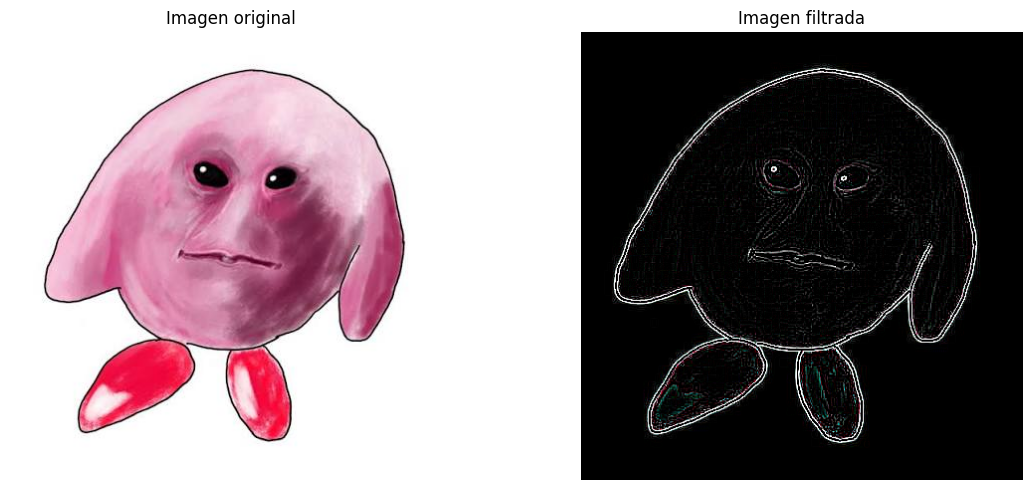

In [11]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# Cargar imagen y convertirla a RGB
ruta = r"images.jpg"
imagen = np.array(Image.open(ruta).convert("RGB"))

# Ingresar kernel 3x3
valores = list(map(float, input(
    "Ingrese los 9 valores del kernel separados por espacios: "
).split()))

if len(valores) != 9:
    raise ValueError("El kernel debe contener exactamente 9 valores.")

kernel = np.array(valores).reshape(3, 3)

# Aplicar convolución por canal
imagen_float = imagen.astype(float)
rellena = np.pad(imagen_float, ((1, 1), (1, 1), (0, 0)), mode="edge")
filtrada = np.zeros_like(imagen_float)

for i in range(imagen.shape[0]):
    for j in range(imagen.shape[1]):
        ventana = rellena[i:i+3, j:j+3, :]
        filtrada[i, j] = np.sum(ventana * kernel[:, :, None], axis=(0, 1))

# Ajustar valores para visualización
filtrada = np.clip(filtrada, 0, 255).astype(np.uint8)

# Mostrar resultados
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(imagen)
axes[0].set_title("Imagen original")
axes[0].axis("off")

axes[1].imshow(filtrada)
axes[1].set_title("Imagen filtrada")
axes[1].axis("off")

plt.tight_layout()
plt.show()

Tomar una imagen y aplicar 2 convoluciones, es decir, filtrar 2 veces con diferente kernel 3x3, y mostrar resultado

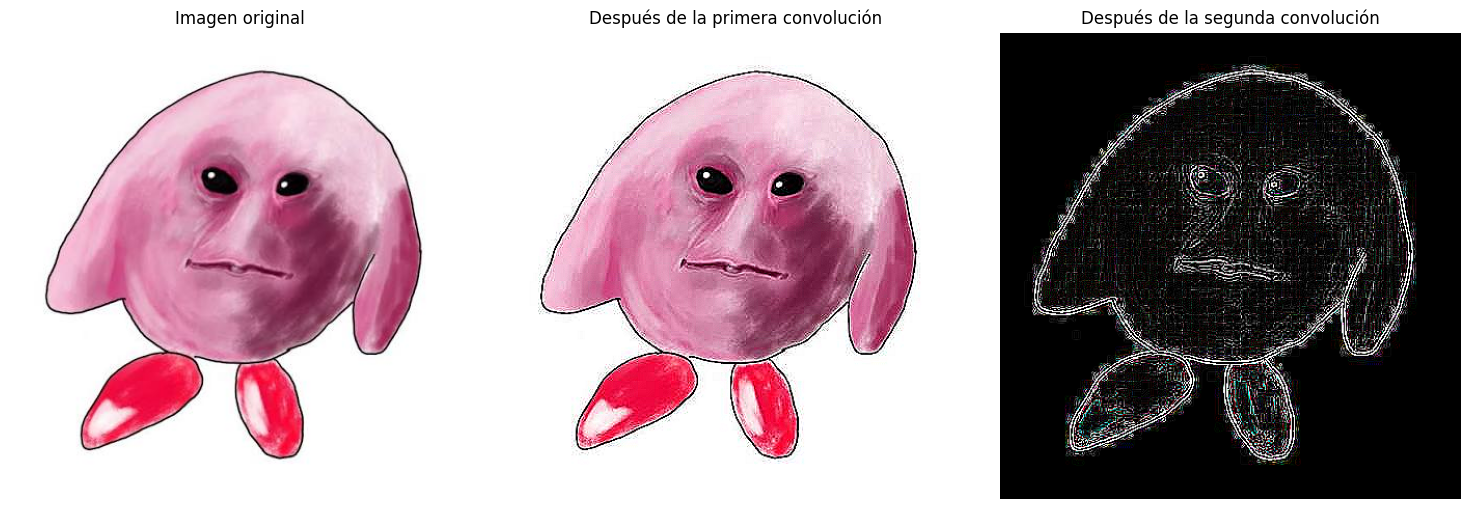

In [ ]:
def ingresar_kernel(numero):
    valores_kernel = list(map(float, input(
        f"Ingrese los 9 valores del kernel {numero}, separados por espacios: "
    ).split()))

    if len(valores_kernel) != 9:
        raise ValueError("Cada kernel debe contener exactamente 9 valores.")

    return np.array(valores_kernel).reshape(3, 3)


def aplicar_convolucion(imagen_entrada, kernel):
    imagen_float = imagen_entrada.astype(float)
    rellena = np.pad(
        imagen_float,
        ((1, 1), (1, 1), (0, 0)),
        mode="edge"
    )

    resultado = np.zeros_like(imagen_float)

    for fila in range(imagen_entrada.shape[0]):
        for columna in range(imagen_entrada.shape[1]):
            ventana = rellena[fila:fila + 3, columna:columna + 3, :]
            resultado[fila, columna] = np.sum(
                ventana * kernel[:, :, None],
                axis=(0, 1)
            )

    return resultado


kernel1 = ingresar_kernel(1)
kernel2 = ingresar_kernel(2)

imagen_filtrada_1 = aplicar_convolucion(imagen, kernel1)
imagen_filtrada_2 = aplicar_convolucion(imagen_filtrada_1, kernel2)

imagen_filtrada_1 = np.clip(imagen_filtrada_1, 0, 255).astype(np.uint8)
imagen_filtrada_2 = np.clip(imagen_filtrada_2, 0, 255).astype(np.uint8)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(imagen)
axes[0].set_title("Imagen original")
axes[0].axis("off")

axes[1].imshow(imagen_filtrada_1)
axes[1].set_title("Después de la primera convolución")
axes[1].axis("off")

axes[2].imshow(imagen_filtrada_2)
axes[2].set_title("Después de la segunda convolución")
axes[2].axis("off")

plt.tight_layout()
plt.show()

Tomar una img rgb, aplicar 3 veces convolucion con 3 kernel diferentes 3x3, en cada salida de la convolucion, aplicar ReLU, luego hacer max pooling de 2x2. Mostrar mapas de caracteristicas resultantes o oimagenes resultantes despues de hacer estas 3 etapas.

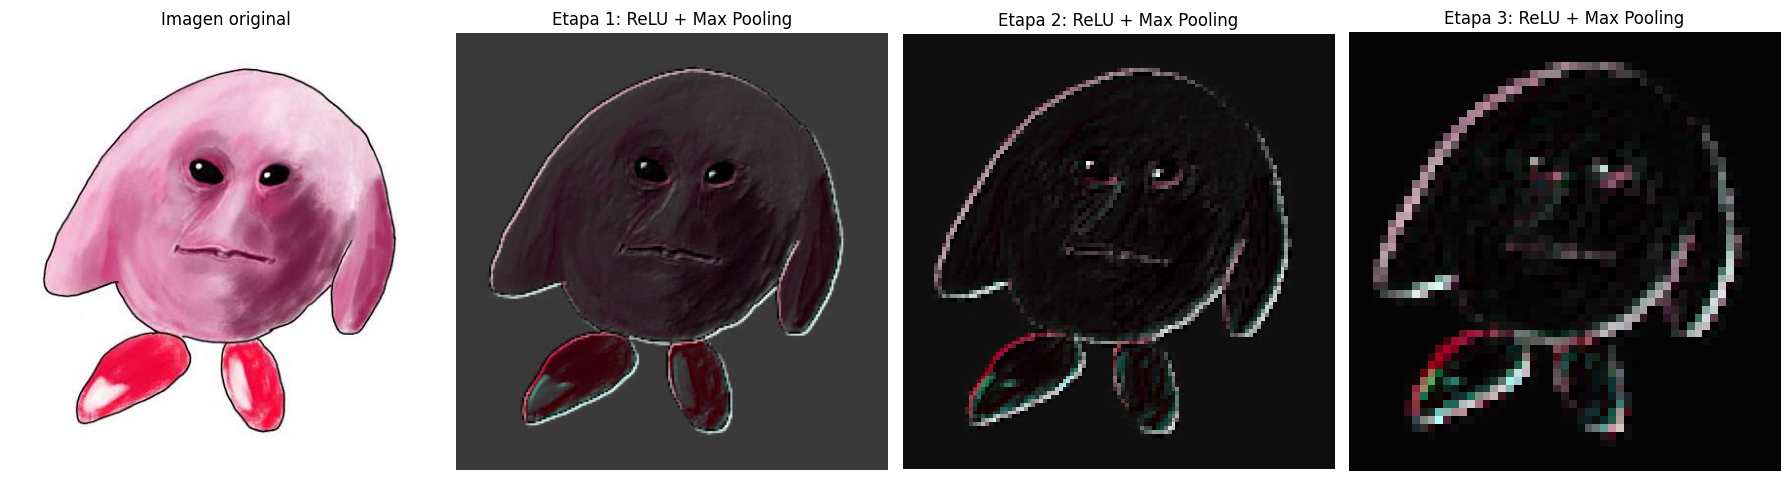

In [ ]:
def max_pooling_2x2(imagen_entrada):
    alto, ancho, canales = imagen_entrada.shape
    nuevo_alto = alto // 2
    nuevo_ancho = ancho // 2

    imagen_recortada = imagen_entrada[
        :nuevo_alto * 2,
        :nuevo_ancho * 2,
        :
    ]

    return imagen_recortada.reshape(
        nuevo_alto, 2, nuevo_ancho, 2, canales
    ).max(axis=(1, 3))


def normalizar_para_mostrar(imagen_entrada):
    maximo = imagen_entrada.max()

    if maximo == 0:
        return imagen_entrada.astype(np.uint8)

    return np.clip(imagen_entrada * 255 / maximo, 0, 255).astype(np.uint8)


# Ingresar tres kernels diferentes
kernel_a = ingresar_kernel(1)
kernel_b = ingresar_kernel(2)
kernel_c = ingresar_kernel(3)

kernels = [kernel_a, kernel_b, kernel_c]
salidas = []
salida_actual = imagen.astype(float)

# Tres etapas: convolución, ReLU y max pooling
for kernel_actual in kernels:
    convolucion = aplicar_convolucion(salida_actual, kernel_actual)
    relu = np.maximum(convolucion, 0)
    salida_actual = max_pooling_2x2(relu)
    salidas.append(salida_actual)

# Mostrar imagen original y mapas de características
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].imshow(imagen)
axes[0].set_title("Imagen original")
axes[0].axis("off")

for indice, salida in enumerate(salidas, start=1):
    axes[indice].imshow(normalizar_para_mostrar(salida))
    axes[indice].set_title(f"Etapa {indice}: ReLU + Max Pooling")
    axes[indice].axis("off")

plt.tight_layout()
plt.show()

Usar VGG o YoloV8(o disponible) para segmentar los elementos detectados en una imagen. Verificar fotografias de mascotas, de personas, elementos de vestir .... El usuario carga la imagen y el alforitmo retorna la imagen segmentada

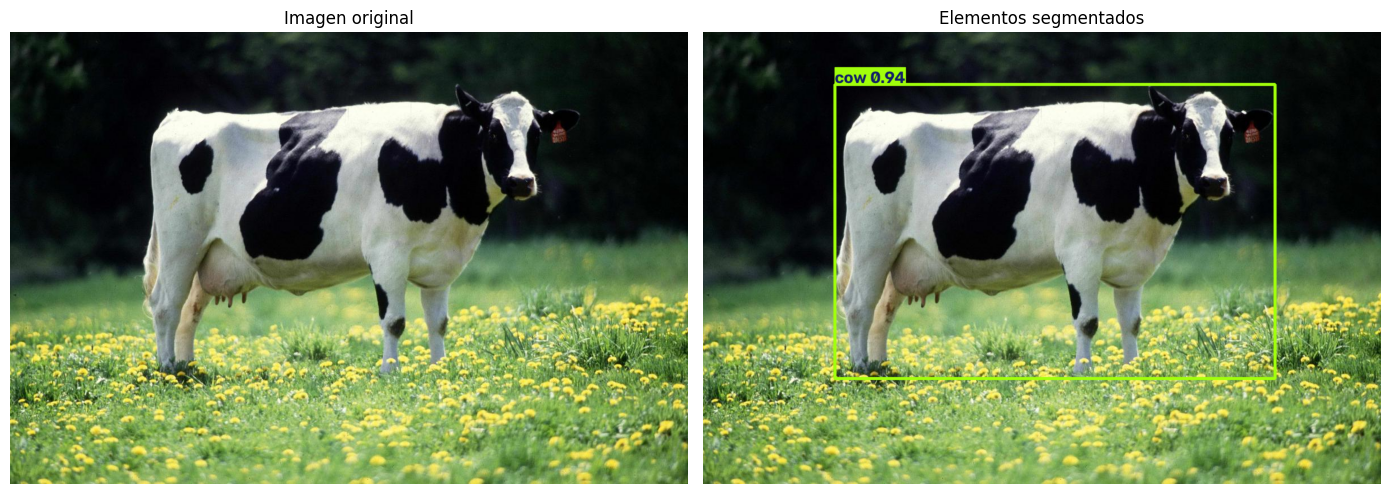

Imagen guardada como: imagen_segmentada.jpg
Elementos detectados: ['cow']


In [10]:
from ultralytics import YOLO
from ultralytics import YOLO

# El usuario introduce la ruta de la imagen
ruta_usuario = "image.png"

modelo = YOLO("yolo11n.pt")

# Ejecutar segmentación con YOLOv8
resultado = modelo.predict(
    source=ruta_usuario,
    conf=0.25,
    task="segment",
    verbose=False
)[0]

# Imagen original en RGB
imagen_original = np.array(Image.open(ruta_usuario).convert("RGB"))

# Imagen con máscaras, etiquetas y cajas
imagen_segmentada = resultado.plot()[:, :, ::-1]

# Mostrar resultados
fig, axes_segmentacion = plt.subplots(1, 2, figsize=(14, 6))

axes_segmentacion[0].imshow(imagen_original)
axes_segmentacion[0].set_title("Imagen original")
axes_segmentacion[0].axis("off")

axes_segmentacion[1].imshow(imagen_segmentada)
axes_segmentacion[1].set_title("Elementos segmentados")
axes_segmentacion[1].axis("off")

plt.tight_layout()
plt.show()

# Guardar la imagen segmentada
Image.fromarray(imagen_segmentada).save("imagen_segmentada.jpg")
print("Imagen guardada como: imagen_segmentada.jpg")

# Mostrar clases detectadas
if resultado.boxes is not None and len(resultado.boxes) > 0:
    clases = [
        resultado.names[int(clase)]
        for clase in resultado.boxes.cls.cpu().numpy()
    ]
    print("Elementos detectados:", clases)
else:
    print("No se detectaron elementos.")

Usar alguna arquitectura de CNN para hacer un tracker tipo esqueleto de la mano, usando la camara integrada

In [ ]:
import cv2
import mediapipe as mp

# Si falta alguna librería, ejecutar previamente:
# %pip install opencv-python mediapipe


mp_hands = mp.solutions.hands
mp_dibujo = mp.solutions.drawing_utils
mp_estilos = mp.solutions.drawing_styles

camara = cv2.VideoCapture(0)

if not camara.isOpened():
    raise RuntimeError("No se pudo acceder a la cámara integrada.")

with mp_hands.Hands(
    static_image_mode=False,
    max_num_hands=2,
    model_complexity=1,
    min_detection_confidence=0.6,
    min_tracking_confidence=0.6
) as manos:

    while True:
        disponible, cuadro = camara.read()

        if not disponible:
            break

        cuadro = cv2.flip(cuadro, 1)
        rgb = cv2.cvtColor(cuadro, cv2.COLOR_BGR2RGB)
        resultado_manos = manos.process(rgb)

        if resultado_manos.multi_hand_landmarks:
            for puntos_mano in resultado_manos.multi_hand_landmarks:
                mp_dibujo.draw_landmarks(
                    cuadro,
                    puntos_mano,
                    mp_hands.HAND_CONNECTIONS,
                    mp_estilos.get_default_hand_landmarks_style(),
                    mp_estilos.get_default_hand_connections_style()
                )

        cv2.imshow("Tracker de esqueleto de la mano", cuadro)

        if cv2.waitKey(1) & 0xFF == ord("q"):
            break

camara.release()
cv2.destroyAllWindows()

AttributeError: module 'mediapipe' has no attribute 'solutions'

Hacer uso de yolo para detectar objetos en algun video que el usuario cargue

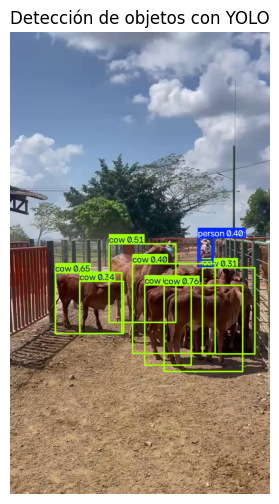

Video procesado y guardado como: video_detectado.mp4


In [7]:
import matplotlib.pyplot as plt
from ultralytics import YOLO


# El usuario introduce la ruta del video
ruta_video = "video.mp4"
ruta_salida = "video_detectado.mp4"

# Modelo YOLO para detección
modelo_det = YOLO("yolo11n.pt")

captura = cv2.VideoCapture(ruta_video)

if not captura.isOpened():
    raise RuntimeError("No se pudo abrir el video.")

fps = captura.get(cv2.CAP_PROP_FPS) or 30
ancho = int(captura.get(cv2.CAP_PROP_FRAME_WIDTH))
alto = int(captura.get(cv2.CAP_PROP_FRAME_HEIGHT))

codec = cv2.VideoWriter_fourcc(*"mp4v")
escritor = cv2.VideoWriter(
    ruta_salida,
    codec,
    fps,
    (ancho, alto)
)

primer_cuadro = None

while True:
    disponible, cuadro = captura.read()

    if not disponible:
        break

    resultado_video = modelo_det.predict(
        source=cuadro,
        conf=0.25,
        verbose=False
    )[0]

    cuadro_anotado = resultado_video.plot()
    escritor.write(cuadro_anotado)

    if primer_cuadro is None:
        primer_cuadro = cuadro_anotado.copy()

captura.release()
escritor.release()

# Mostrar un cuadro de ejemplo
if primer_cuadro is not None:
    plt.figure(figsize=(12, 6))
    plt.imshow(cv2.cvtColor(primer_cuadro, cv2.COLOR_BGR2RGB))
    plt.title("Detección de objetos con YOLO")
    plt.axis("off")
    plt.show()

print(f"Video procesado y guardado como: {ruta_salida}")